# Neural Network for Rating Search Query Relevance

**Author** : Huy Le

## Project goal
 

This project builds a machine-learning model that assigns a quality rating
to a user search query.

 
The rating is a decimal number between 0 (vague, unclear) and 1 (clear, specific).

The project uses two CSV files: 
- `train.csv`: contains queries and known ratings.
- `test.csv`: contains queries whose ratings must be predicted.
 

The notebook compares two neural-network architectures:
1. An embedding model with average pooling.
2. An embedding model with a bidirectional GRU (gated recurrent unit).
 

The models are evaluated using Mean Absolute Error, abbreviated as MAE. A smaller MAE represents more accurate predictions.
 
## Important data-handling rule
 

The notebook does not add columns to or remove columns from the original training and testing DataFrames.

 
All cleaned text, query lengths, model inputs, and predictions are stored in separate Python variables.

## 1. Imports, reproducibility, and configuration

Seeds improve repeatability. Change `DATA_DIR` only if the three CSV files are not in the notebook folder.

In [1]:
"""
This module imports all Python libraries required by the project and defines
the main configuration values used throughout the notebook.

Why this module must run first
------------------------------
Later modules refer to names such as pd, np, tf, TRAIN_PATH, and SEED.
Those names do not exist until this module has been executed.

-------------------------
A Python library is a collection of tools written by other developers.
Instead of writing every operation from scratch, we import libraries that
already know how to:

* read CSV files,
* organize information into tables,
* create graphs,
* split information into training and validation groups,
* build neural networks,
* measure prediction error, and
* save models and predictions.

Source-data protection
----------------------
Nothing in this module changes train.csv or test.csv. It only defines where
those files are expected to be found.
"""

# Standard Python libraries
import os
import re
import random
import warnings
from pathlib import Path

# Data manipulation and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Traditional machine-learning tools
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

# Neural-network tools
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


# Hide noncritical warning messages so the notebook is easier to read.
warnings.filterwarnings("ignore")


# ---------------------------------------------------------
# Reproducibility
# ---------------------------------------------------------

# A seed makes random operations more repeatable.
#
# The exact numerical results can still vary slightly across computers,
# operating systems, TensorFlow versions, or hardware types.
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


# ---------------------------------------------------------
# File locations
# ---------------------------------------------------------

# The project expects train.csv and test.csv inside the data folder.
DATA_DIR = Path("data")

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"

# Generated outputs are placed in a separate outputs folder.
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SUBMISSION_PATH = OUTPUT_DIR / "submission.csv"
MODEL_PATH = OUTPUT_DIR / "best_query_rating_model.keras"
RESULTS_PATH = OUTPUT_DIR / "model_experiment_results.csv"


# ---------------------------------------------------------
# Model configuration
# ---------------------------------------------------------

# Twenty percent of the labeled information is reserved for validation.
VALIDATION_SIZE = 0.20

# Number of observations processed before a model-weight update.
BATCH_SIZE = 64

# Maximum number of passes through the training information.
# Early stopping may end training before this number is reached.
MAX_EPOCHS = 25

# Maximum number of vocabulary tokens retained by the neural vectorizer.
MAX_TOKENS = 20_000

# Number of numerical values used to represent each learned token.
EMBEDDING_DIM = 64


print("Configuration completed successfully.")
print("TensorFlow version:", tf.__version__)
print("Pandas version:", pd.__version__)
print("Training path:", TRAIN_PATH)
print("Testing path:", TEST_PATH)
print("Output folder:", OUTPUT_DIR.resolve())

Configuration completed successfully.
TensorFlow version: 2.22.0-rc0
Pandas version: 3.1.0
Training path: data\train.csv
Testing path: data\test.csv
Output folder: C:\Drive_D\Gia Huy\pythonfiles\HoneywellAIEngineerassessment\outputs


## 2. Load and validate the files

The checks below fail early with a clear message if a required file or field is absent. The original order of `test.csv` is preserved for submission alignment.

In [2]:
"""

Purpose
-------
This module reads train.csv and test.csv into memory and verifies that their
column structures match the project requirements.

Variables created
-----------------
data:
    A Pandas DataFrame created from train.csv. It should contain the columns
    query and rating.

test_data:
    A Pandas DataFrame created from test.csv. It should contain only query.

What is a DataFrame?
--------------------
A DataFrame is a table in Python. It resembles a spreadsheet with rows and
columns.

Important source-file behavior
------------------------------
pd.read_csv reads a file into computer memory. Reading the file does not
change the CSV stored on disk.

This module also avoids adding, deleting, or renaming columns.
"""

# Confirm that both required files exist.
missing_files = [
    str(path)
    for path in [TRAIN_PATH, TEST_PATH]
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "The following required file or files could not be found: "
        + ", ".join(missing_files)
        + ". Confirm that the data folder contains train.csv and test.csv."
    )


# Read the original CSV files into Pandas DataFrames.
data = pd.read_csv(TRAIN_PATH)
test_data = pd.read_csv(TEST_PATH)


# Define the exact schemas required by the project.
expected_train_columns = ["query", "rating"]
expected_test_columns = ["query"]


# Require exact column names and exact column order.
if list(data.columns) != expected_train_columns:
    raise ValueError(
        "train.csv must contain exactly these columns in this order: "
        f"{expected_train_columns}. Found: {data.columns.tolist()}"
    )

if list(test_data.columns) != expected_test_columns:
    raise ValueError(
        "test.csv must contain exactly this column: "
        f"{expected_test_columns}. Found: {test_data.columns.tolist()}"
    )


# Save the original structure for a verification check near the end.
original_train_columns = tuple(data.columns)
original_test_columns = tuple(test_data.columns)

original_train_shape = data.shape
original_test_shape = test_data.shape


print("The datasets were loaded successfully.")
print("Training shape:", data.shape)
print("Testing shape:", test_data.shape)

print("\nFirst five training rows:")
display(data.head())

print("\nFirst five testing rows:")
display(test_data.head())

The datasets were loaded successfully.
Training shape: (5000, 2)
Testing shape: (999, 1)

First five training rows:


,query,rating
0,where to buy a reliable smartphone,0.9382
1,how to fix a syntax error in rust,0.8168
2,how to calculate mean absolute error in C#,0.8305
3,best electric vehicles resources,0.6663
4,wireless headphones examples,0.4834



First five testing rows:


,query
0,NaN
1,x
2,?
3,12345
4,weather


## 3. Create modeling arrays without changing the DataFrames

This module extracts query text and ratings into separate NumPy arrays.

In [3]:
"""
Why separate arrays are used
----------------------------
The original DataFrames should remain unchanged. Therefore, this notebook
does not add columns such as query_clean, word_count, or prediction to data
or test_data.

Instead, it creates separate variables:

all_train_queries:
    Cleaned versions of all queries from train.csv.

all_train_ratings:
    Numerical versions of all ratings from train.csv.

model_queries:
    Queries whose rows contain usable ratings.

model_ratings:
    Valid numerical ratings restricted to the interval from 0 to 1.

test_queries:
    Cleaned queries from test.csv.

Meaning of query cleaning
-------------------------
The cleaning function:

* replaces missing query values with an empty string,
* converts each query to text,
* replaces repeated whitespace with one space, and
* removes whitespace from the beginning and end.

It does not aggressively delete words, numbers, or punctuation.
"""


def clean_query(value):
    """
    Convert one query into a consistent text value.

    Parameters
    ----------
    value:
        One value from the query column. It may be text, a number, a missing
        value, or another value that can be converted to text.

    Returns
    -------
    str
        A cleaned string.

    Examples
    --------
    "  learn   Python  " becomes "learn Python".

    A missing value becomes an empty string.

    Why re.sub is used
    ------------------
    re is Python's regular-expression library. The pattern r"\\s+" means
    "one or more whitespace characters." Those characters are replaced by
    one ordinary space.
    """

    if pd.isna(value):
        return ""

    return re.sub(
        r"\s+",
        " ",
        str(value)
    ).strip()


# Clean the query columns without assigning anything back to the DataFrames.
all_train_queries = (
    data["query"]
    .map(clean_query)
    .to_numpy()
)

test_queries = (
    test_data["query"]
    .map(clean_query)
    .to_numpy()
)


# Convert ratings to numbers in a separate object.
# Unreadable values become NaN, meaning "not a number."
all_train_ratings = pd.to_numeric(
    data["rating"],
    errors="coerce"
).to_numpy(dtype="float32")


# Identify which ratings are usable.
valid_rating_mask = ~np.isnan(all_train_ratings)

invalid_rating_count = int(
    (~valid_rating_mask).sum()
)


# Filter only the temporary modeling arrays.
# No row is removed from the original data DataFrame.
model_queries = all_train_queries[valid_rating_mask]
model_ratings = all_train_ratings[valid_rating_mask]


# Count ratings outside the required interval before clipping them.
out_of_range_count = int(
    (
        (model_ratings < 0)
        | (model_ratings > 1)
    ).sum()
)

# Keep the temporary model ratings between 0 and 1.
model_ratings = np.clip(
    model_ratings,
    0.0,
    1.0
).astype("float32")


print("Original training rows:", len(data))
print("Usable modeling rows:", len(model_queries))
print("Invalid ratings excluded from modeling:", invalid_rating_count)
print("Out-of-range ratings clipped:", out_of_range_count)
print("Test queries:", len(test_queries))

Original training rows: 5000
Usable modeling rows: 5000
Invalid ratings excluded from modeling: 0
Out-of-range ratings clipped: 0
Test queries: 999


## 4. Explore ratings and query lengths

This module summarizes and visualizes the synthetic training information.

Rating summary:


count    5000.000000
mean        0.743080
std         0.253357
min         0.000000
25%         0.635350
50%         0.826300
75%         0.922925
max         1.000000
Name: rating, dtype: float64


Word-count summary:


count    5000.000000
mean        5.662200
std         2.757682
min         0.000000
25%         3.000000
50%         6.000000
75%         8.000000
max        12.000000
Name: word_count, dtype: float64


Character-count summary:


count    5000.000000
mean       35.980000
std        16.956164
min         0.000000
25%        26.000000
50%        35.000000
75%        49.000000
max        82.000000
Name: character_count, dtype: float64

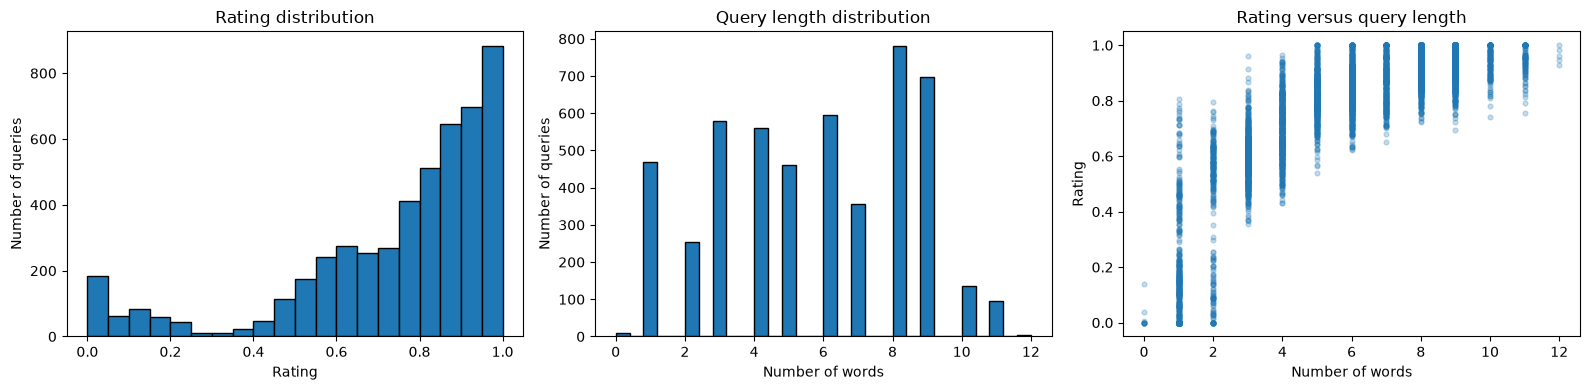

95th-percentile query length: 9
Neural-network sequence length: 10


In [4]:
"""
Why exploration matters
-----------------------
A model should not be trained without first checking the information it will
learn from. Exploration can reveal:

* whether ratings cover the full 0-to-1 range,
* whether most queries are unusually short or long,
* whether query length appears related to rating, and
* whether a few very long queries could cause excessive sequence padding.

No source columns are created
-----------------------------
Word and character counts are stored in independent NumPy arrays. They are
not added to data.
"""

# Count whitespace-separated words in every usable training query.
word_counts = np.array(
    [
        len(query.split())
        for query in model_queries
    ]
)

# Count characters in every usable training query.
character_counts = np.array(
    [
        len(query)
        for query in model_queries
    ]
)


print("Rating summary:")
display(
    pd.Series(
        model_ratings,
        name="rating"
    ).describe()
)

print("\nWord-count summary:")
display(
    pd.Series(
        word_counts,
        name="word_count"
    ).describe()
)

print("\nCharacter-count summary:")
display(
    pd.Series(
        character_counts,
        name="character_count"
    ).describe()
)


# Create three visual summaries.
fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 4)
)

axes[0].hist(
    model_ratings,
    bins=20,
    edgecolor="black"
)
axes[0].set_title("Rating distribution")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Number of queries")

axes[1].hist(
    word_counts,
    bins=30,
    edgecolor="black"
)
axes[1].set_title("Query length distribution")
axes[1].set_xlabel("Number of words")
axes[1].set_ylabel("Number of queries")

axes[2].scatter(
    word_counts,
    model_ratings,
    alpha=0.25,
    s=12
)
axes[2].set_title("Rating versus query length")
axes[2].set_xlabel("Number of words")
axes[2].set_ylabel("Rating")

plt.tight_layout()
plt.show()


# Determine the length that covers approximately 95 percent of queries.
length_95 = int(
    np.ceil(
        np.percentile(
            word_counts,
            95
        )
    )
)

# Use practical lower and upper limits.
SEQUENCE_LENGTH = int(
    np.clip(
        length_95,
        10,
        100
    )
)

print("95th-percentile query length:", length_95)
print("Neural-network sequence length:", SEQUENCE_LENGTH)

## 5. Split the labeled information

This module divides the labeled information into two groups:

- Training group:
    Used by the model to learn relationships between query text and ratings.

- Validation group:
    Hidden from the learning process and used to estimate how well the model
    handles observations it did not train on.

In [5]:
"""
Why not train on everything immediately?
----------------------------------------
A model can appear accurate if it is evaluated on the same information that
it memorized. A validation group provides a more meaningful test.

The test.csv file is not used here
----------------------------------
The test queries do not have known ratings. They are saved for final
prediction after model selection.
"""

X_train, X_valid, y_train, y_valid = train_test_split(
    model_queries,
    model_ratings,
    test_size=VALIDATION_SIZE,
    random_state=SEED
)


print("Training observations:", len(X_train))
print("Validation observations:", len(X_valid))
print("Final test observations:", len(test_queries))

print(
    "Average training rating:",
    round(float(np.mean(y_train)), 4)
)

print(
    "Average validation rating:",
    round(float(np.mean(y_valid)), 4)
)

Training observations: 4000
Validation observations: 1000
Final test observations: 999
Average training rating: 0.7418
Average validation rating: 0.7483


## 6. Build reference baselines

This module creates simple reference methods before training neural networks.

In [6]:
"""
Why baselines matter
--------------------
A complicated model should improve on a simple approach. If it does not, the
extra complexity may not be justified.

Baseline 1: Mean prediction
---------------------------
This method predicts the average training rating for every query. It does not
read the query text.

Baseline 2: TF-IDF plus Ridge regression
----------------------------------------
TF-IDF converts text fragments into numerical features. Ridge regression then
learns a weighted relationship between those features and the ratings.

This second baseline is not the final required neural network. It is included
only as a useful comparison.
"""

# ---------------------------------------------------------
# Baseline 1: Predict the training mean
# ---------------------------------------------------------

training_mean = float(
    np.mean(y_train)
)

mean_predictions = np.full(
    shape=len(y_valid),
    fill_value=training_mean,
    dtype="float32"
)

mean_baseline_mae = mean_absolute_error(
    y_valid,
    mean_predictions
)


# ---------------------------------------------------------
# Baseline 2: Character TF-IDF plus Ridge regression
# ---------------------------------------------------------

tfidf_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=2,
    max_features=50_000,
    sublinear_tf=True
)

X_train_tfidf = tfidf_vectorizer.fit_transform(
    X_train
)

X_valid_tfidf = tfidf_vectorizer.transform(
    X_valid
)

ridge_model = Ridge(
    alpha=3.0
)

ridge_model.fit(
    X_train_tfidf,
    y_train
)

ridge_predictions = ridge_model.predict(
    X_valid_tfidf
)

ridge_predictions = np.clip(
    ridge_predictions,
    0.0,
    1.0
)

ridge_baseline_mae = mean_absolute_error(
    y_valid,
    ridge_predictions
)


print(
    f"Mean baseline validation MAE: "
    f"{mean_baseline_mae:.6f}"
)

print(
    f"TF-IDF plus Ridge validation MAE: "
    f"{ridge_baseline_mae:.6f}"
)

Mean baseline validation MAE: 0.190352
TF-IDF plus Ridge validation MAE: 0.067539


## 7. Create neural text preprocessing

Neural networks cannot work directly with written words. They require numeric
inputs. A TextVectorization layer converts every query into a fixed-length
sequence of integer token identifiers.

In [7]:
"""

Neural networks cannot work directly with written words. They require numeric
inputs. A TextVectorization layer converts every query into a fixed-length
sequence of integer token identifiers.

Example
-------
A query such as:

    "learn python programming"

could become something similar to:

    [52, 18, 91, 0, 0, 0, ...]

The specific integers depend on the learned vocabulary.

Training-only adaptation
------------------------
The vocabulary is learned only from X_train. This prevents information from
the validation and test groups from influencing preprocessing during model
evaluation.

Padding
-------
Queries have different lengths. Short queries are padded with zeros so every
model input has the same length.
"""

vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=SEQUENCE_LENGTH,
    standardize="lower_and_strip_punctuation",
    split="whitespace",
    name="text_vectorizer"
)

vectorizer.adapt(
    tf.data.Dataset
    .from_tensor_slices(X_train)
    .batch(256)
)

VOCAB_SIZE = len(
    vectorizer.get_vocabulary()
)

print("Learned vocabulary size:", VOCAB_SIZE)

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Learned vocabulary size: 711


## 8. Define the neural networks

This module defines two candidate neural networks.

In [8]:
"""
Model 1: AveragePoolingNN
-------------------------
This model:

1. converts words to token numbers,
2. converts the token numbers to learned embedding vectors,
3. averages those vectors into one query representation,
4. passes that representation through dense layers, and
5. produces a rating from 0 to 1.

This model is relatively compact and fast.

Model 2: BidirectionalGRUNN
---------------------------
This model uses a bidirectional gated recurrent unit, abbreviated as GRU.
The GRU examines the order of tokens from both directions.

This allows the model to distinguish between queries that use similar words
in different arrangements.

Overfitting controls
--------------------
L2 regularization discourages unnecessarily large model weights.

Dropout temporarily disables random hidden units during training. This
discourages the model from relying too heavily on a small number of paths.

Sigmoid output
--------------
The final sigmoid function restricts predictions to the interval from 0 to 1.
"""


def compile_model(model):
    """
    Configure a neural network for training.

    Parameters
    ----------
    model:
        A Keras neural-network model whose architecture has already been
        defined.

    Returns
    -------
    keras.Model
        The same model after its optimizer, loss, and metrics are configured.

    Optimizer
    ---------
    Adam controls how model weights are adjusted during learning.

    Loss
    ----
    Mean Absolute Error is used as the learning objective because it directly
    matches the required evaluation metric.
    """

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss=keras.losses.MeanAbsoluteError(),
        metrics=[
            keras.metrics.MeanAbsoluteError(
                name="mae"
            )
        ]
    )

    return model


def build_average_model():
    """
    Build the compact average-pooling text-regression model.

    Returns
    -------
    keras.Model
        A compiled model that accepts raw query strings and predicts one
        rating per query.
    """

    query_input = keras.Input(
        shape=(),
        dtype=tf.string,
        name="query"
    )

    x = vectorizer(query_input)

    x = layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True,
        name="embedding"
    )(x)

    x = layers.GlobalAveragePooling1D(
        name="average_pooling"
    )(x)

    x = layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(0.0001),
        name="dense_64"
    )(x)

    x = layers.Dropout(
        0.30,
        name="dropout_30"
    )(x)

    x = layers.Dense(
        32,
        activation="relu",
        name="dense_32"
    )(x)

    x = layers.Dropout(
        0.20,
        name="dropout_20"
    )(x)

    output = layers.Dense(
        1,
        activation="sigmoid",
        name="rating"
    )(x)

    model = keras.Model(
        inputs=query_input,
        outputs=output,
        name="AveragePoolingNN"
    )

    return compile_model(model)


def build_bigru_model():
    """
    Build the bidirectional GRU text-regression model.

    Returns
    -------
    keras.Model
        A compiled model that reads raw query strings, models token order in
        two directions, and predicts one rating per query.
    """

    query_input = keras.Input(
        shape=(),
        dtype=tf.string,
        name="query"
    )

    x = vectorizer(query_input)

    x = layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True,
        name="embedding"
    )(x)

    x = layers.Bidirectional(
        layers.GRU(
            48,
            dropout=0.20
        ),
        name="bidirectional_gru"
    )(x)

    x = layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(0.0001),
        name="dense_64"
    )(x)

    x = layers.Dropout(
        0.35,
        name="dropout_35"
    )(x)

    output = layers.Dense(
        1,
        activation="sigmoid",
        name="rating"
    )(x)

    model = keras.Model(
        inputs=query_input,
        outputs=output,
        name="BidirectionalGRUNN"
    )

    return compile_model(model)


model_builders = {
    "AveragePoolingNN": build_average_model,
    "BidirectionalGRUNN": build_bigru_model
}


# Show one architecture before training.
preview_model = build_average_model()
preview_model.summary()
del preview_model

Model: "AveragePoolingNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ query (InputLayer)                   │ (None)                      │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ text_vectorizer (TextVectorization)  │ (None, 10)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ embedding (Embedding)                │ (None, 10, 64)              │          45,504 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ average_pooling                      │ (None, 64)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_64 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_30 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_32 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_20 (Dropout)                 │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rating (Dense)                       │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 51,777 (202.25 KB)

 Trainable params: 51,777 (202.25 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Train and compare the models

This module trains both candidate neural networks above using the same training and
validation information.


Training: AveragePoolingNN
Epoch 1/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: nan - mae: 0.2847 - val_loss: nan - val_mae: 0.2479 - learning_rate: 0.0010
Epoch 2/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: nan - mae: 0.2200 - val_loss: nan - val_mae: 0.1948 - learning_rate: 0.0010
Epoch 3/25
61/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: nan - mae: 0.1891
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: nan - mae: 0.1888 - val_loss: nan - val_mae: 0.1780 - learning_rate: 0.0010
Epoch 4/25
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: nan - mae: 0.1829 - val_loss: nan - val_mae: 0.1763 - learning_rate: 5.0000e-04
Epoch 5/25
56/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: nan - mae: 0.1814
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: nan - mae: 0.1824 - val_loss: nan - val_mae: 0.1756 - learning_rate: 5.0000e-04
Epoch 5: ea

,model,validation_mae,best_epoch,parameters
0,BidirectionalGRUNN,0.058763,22,84609
1,AveragePoolingNN,0.247871,1,51777


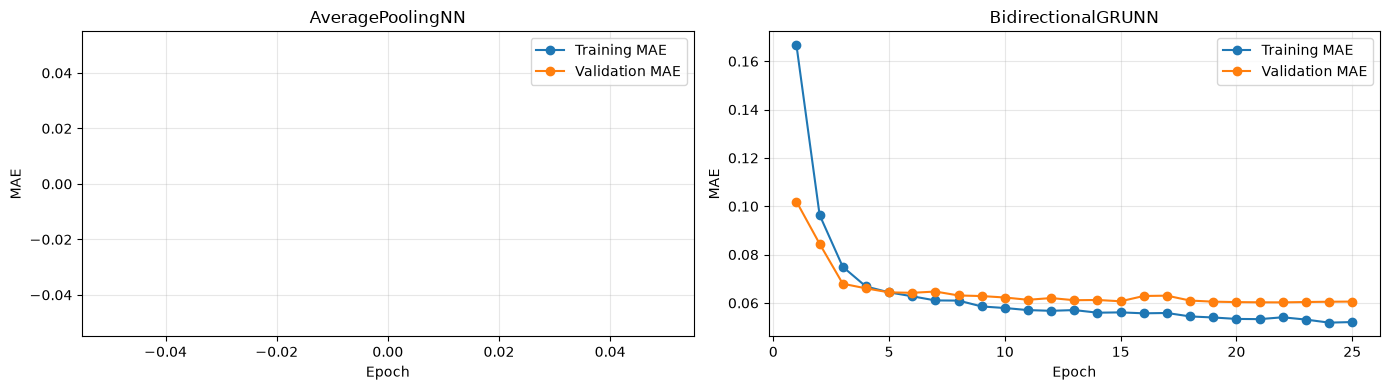

Selected neural network: BidirectionalGRUNN
Selected epoch count: 22
Selected validation MAE: 0.058763


,model,validation_mae
0,BidirectionalGRUNN,0.058763
1,TF-IDF plus Ridge,0.067539
2,Mean baseline,0.190352


In [9]:
"""
What one epoch means
--------------------
An epoch is one complete pass through the training group.

Early stopping
--------------
Training ends when validation loss stops improving. The model then restores
the weights from its best validation epoch.

This helps reduce overfitting and prevents unnecessary training.

Learning-rate reduction
-----------------------
If validation improvement slows, ReduceLROnPlateau lowers the learning rate.
This allows the optimizer to make smaller adjustments.

Selection rule
--------------
The neural network with the smallest validation MAE is selected.
"""

histories = {}
trained_models = {}
experiment_results = []


for model_name, build_model in model_builders.items():

    print("\n" + "=" * 75)
    print("Training:", model_name)

    tf.keras.utils.set_random_seed(SEED)

    model = build_model()

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            min_delta=0.0001,
            restore_best_weights=True,
            verbose=1
        ),

        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=0.000001,
            verbose=1
        )
    ]

    history = model.fit(
        X_train,
        y_train,
        validation_data=(
            X_valid,
            y_valid
        ),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=callbacks,
        verbose=1
    )

    validation_predictions = model.predict(
        X_valid,
        batch_size=BATCH_SIZE,
        verbose=0
    ).reshape(-1)

    validation_predictions = np.clip(
        validation_predictions,
        0.0,
        1.0
    )

    validation_mae = mean_absolute_error(
        y_valid,
        validation_predictions
    )

    best_epoch = int(
        np.argmin(
            history.history["val_loss"]
        ) + 1
    )

    histories[model_name] = history.history
    trained_models[model_name] = model

    experiment_results.append(
        {
            "model": model_name,
            "validation_mae": validation_mae,
            "best_epoch": best_epoch,
            "parameters": model.count_params()
        }
    )


results_df = (
    pd.DataFrame(experiment_results)
    .sort_values("validation_mae")
    .reset_index(drop=True)
)

print("\nNeural-network results:")
display(results_df)


# Plot training and validation error for each architecture.
fig, axes = plt.subplots(
    1,
    len(histories),
    figsize=(7 * len(histories), 4),
    squeeze=False
)

for axis, (model_name, history) in zip(
    axes.ravel(),
    histories.items()
):

    epoch_numbers = np.arange(
        1,
        len(history["loss"]) + 1
    )

    axis.plot(
        epoch_numbers,
        history["loss"],
        marker="o",
        label="Training MAE"
    )

    axis.plot(
        epoch_numbers,
        history["val_loss"],
        marker="o",
        label="Validation MAE"
    )

    axis.set_title(model_name)
    axis.set_xlabel("Epoch")
    axis.set_ylabel("MAE")
    axis.grid(alpha=0.3)
    axis.legend()

plt.tight_layout()
plt.show()


# Select the neural network with the smallest validation MAE.
best_model_name = results_df.loc[0, "model"]
best_model = trained_models[best_model_name]

best_neural_mae = float(
    results_df.loc[0, "validation_mae"]
)

best_epoch = int(
    results_df.loc[0, "best_epoch"]
)


overall_comparison = pd.DataFrame(
    {
        "model": [
            "Mean baseline",
            "TF-IDF plus Ridge",
            best_model_name
        ],
        "validation_mae": [
            mean_baseline_mae,
            ridge_baseline_mae,
            best_neural_mae
        ]
    }
).sort_values(
    "validation_mae"
).reset_index(
    drop=True
)


print("Selected neural network:", best_model_name)
print("Selected epoch count:", best_epoch)
print(f"Selected validation MAE: {best_neural_mae:.6f}")

display(overall_comparison)

## 10. Diagnose validation performance

A single MAE value does not explain every model behavior. This module creates
additional charts to show where predictions differ from actual ratings.

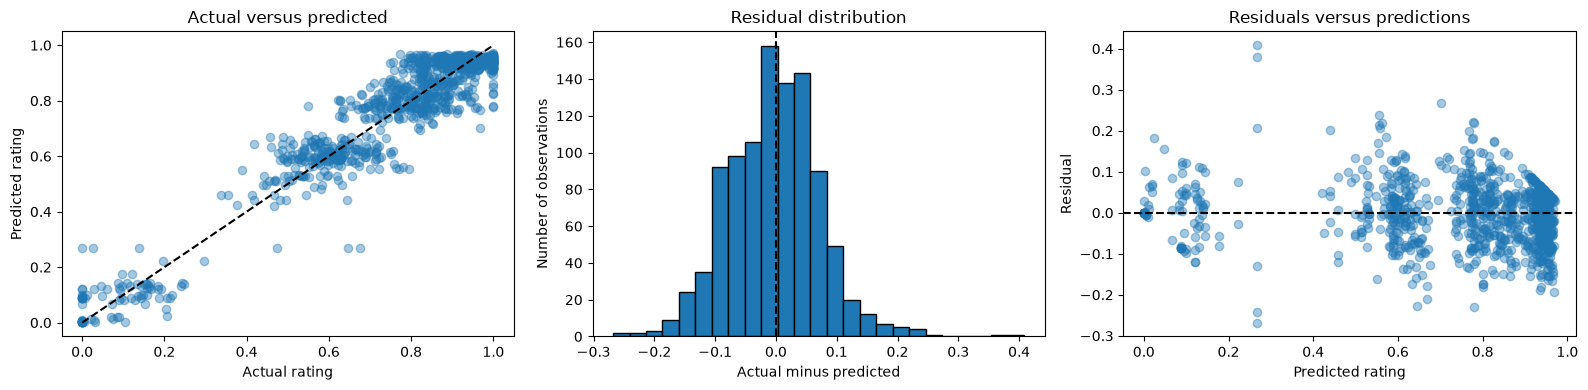

Validation MAE: 0.058763
Mean residual: -0.003382
Largest absolute error: 0.408553


In [10]:
"""
Residual
--------
A residual is calculated as:

    actual rating - predicted rating

A positive residual means the model predicted too low.

A negative residual means the model predicted too high.

A well-behaved model should generally have residuals centered near zero,
without a strong visible pattern.
"""

best_validation_predictions = best_model.predict(
    X_valid,
    batch_size=BATCH_SIZE,
    verbose=0
).reshape(-1)

best_validation_predictions = np.clip(
    best_validation_predictions,
    0.0,
    1.0
)

residuals = (
    y_valid
    - best_validation_predictions
)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 4)
)


# Actual versus predicted ratings
axes[0].scatter(
    y_valid,
    best_validation_predictions,
    alpha=0.4
)

axes[0].plot(
    [0, 1],
    [0, 1],
    color="black",
    linestyle="--"
)

axes[0].set_title("Actual versus predicted")
axes[0].set_xlabel("Actual rating")
axes[0].set_ylabel("Predicted rating")


# Residual distribution
axes[1].hist(
    residuals,
    bins=25,
    edgecolor="black"
)

axes[1].axvline(
    0,
    color="black",
    linestyle="--"
)

axes[1].set_title("Residual distribution")
axes[1].set_xlabel("Actual minus predicted")
axes[1].set_ylabel("Number of observations")


# Residuals versus predictions
axes[2].scatter(
    best_validation_predictions,
    residuals,
    alpha=0.4
)

axes[2].axhline(
    0,
    color="black",
    linestyle="--"
)

axes[2].set_title("Residuals versus predictions")
axes[2].set_xlabel("Predicted rating")
axes[2].set_ylabel("Residual")

plt.tight_layout()
plt.show()


final_validation_mae = mean_absolute_error(
    y_valid,
    best_validation_predictions
)

mean_residual = float(
    np.mean(residuals)
)

largest_absolute_error = float(
    np.max(
        np.abs(residuals)
    )
)


print(f"Validation MAE: {final_validation_mae:.6f}")
print(f"Mean residual: {mean_residual:.6f}")
print(f"Largest absolute error: {largest_absolute_error:.6f}")

## 11. Refit, predict, verify, and save outputs ##

After selecting the best architecture, this module rebuilds it and trains it
using all usable labeled observations.


In [11]:
"""

Why rebuild the vectorizer?
---------------------------
The evaluation vocabulary was learned only from the training partition. After
model selection, the final vocabulary can be learned from all labeled query
text.

Why use the selected epoch count?
---------------------------------
The validation experiment identified an epoch count that balanced learning
and overfitting. Reusing it is more defensible than automatically training for
the maximum number of epochs.

Source-data protection
----------------------
This module does not assign predictions to test_data. Instead, it creates a
new DataFrame called submission_output.

Files produced
--------------
outputs/submission.csv:
    Contains query and predicted rating.

outputs/best_query_rating_model.keras:
    Contains the final model and its text-preprocessing layer.

outputs/model_experiment_results.csv:
    Contains the neural-network comparison.
"""

# Rebuild preprocessing using all usable labeled text.
final_vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=SEQUENCE_LENGTH,
    standardize="lower_and_strip_punctuation",
    split="whitespace",
    name="text_vectorizer"
)

final_vectorizer.adapt(
    tf.data.Dataset
    .from_tensor_slices(model_queries)
    .batch(256)
)

# The model-building functions read the current vectorizer and vocabulary.
vectorizer = final_vectorizer

VOCAB_SIZE = len(
    vectorizer.get_vocabulary()
)


# Build a fresh copy of the selected architecture.
tf.keras.utils.set_random_seed(SEED)

final_model = model_builders[
    best_model_name
]()


# Refit using all usable labeled observations.
final_model.fit(
    model_queries,
    model_ratings,
    epochs=best_epoch,
    batch_size=BATCH_SIZE,
    verbose=1
)


# Generate one prediction for each test query.
test_predictions = final_model.predict(
    test_queries,
    batch_size=BATCH_SIZE,
    verbose=0
).reshape(-1)

test_predictions = np.clip(
    test_predictions,
    0.0,
    1.0
)


# Create a new output table instead of modifying test_data.
submission_output = pd.DataFrame(
    {
        "query": test_data["query"].to_numpy(
            copy=True
        ),
        "rating": test_predictions.astype(float)
    }
)


# Verify the required submission structure.
assert list(submission_output.columns) == [
    "query",
    "rating"
]

assert len(submission_output) == len(test_data)

assert submission_output["rating"].notna().all()

assert submission_output["rating"].between(
    0.0,
    1.0
).all()


# Verify that the source DataFrames still have their original structures.
assert tuple(data.columns) == original_train_columns
assert tuple(test_data.columns) == original_test_columns

assert data.shape == original_train_shape
assert test_data.shape == original_test_shape


# Save all generated artifacts.
submission_output.to_csv(
    SUBMISSION_PATH,
    index=False
)

final_model.save(
    MODEL_PATH
)

results_df.to_csv(
    RESULTS_PATH,
    index=False
)


print("All verification checks passed.")
print("The source DataFrames were not structurally modified.")

print("\nSubmission saved to:")
print(SUBMISSION_PATH.resolve())

print("\nModel saved to:")
print(MODEL_PATH.resolve())

print("\nExperiment results saved to:")
print(RESULTS_PATH.resolve())

print("\nFirst five submission rows:")
display(submission_output.head())

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Epoch 1/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 13s 75ms/step - loss: 0.1518 - mae: 0.1454
Epoch 2/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0879 - mae: 0.0828
Epoch 3/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0698 - mae: 0.0651
Epoch 4/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0654 - mae: 0.0614
Epoch 5/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0622 - mae: 0.0587
Epoch 6/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0618 - mae: 0.0587
Epoch 7/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0604 - mae: 0.0576
Epoch 8/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0600 - mae: 0.0574
Epoch 9/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0584 - mae: 0.0560
Epoch 10/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0591 - mae: 0.0569
Epoch 11/22
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0581 - mae: 0.0561
Epoch 12/22
79/79 ━━━━━━━━━━━━━━━━━━━

UnicodeEncodeError: 'charmap' codec can't encode characters in position 2830-2839: character maps to <undefined>

## Interpretation

MAE is the average absolute difference between true and predicted ratings. It is nonnegative, and **lower is better**, with zero representing perfect predictions.

Useful next experiments include character-level neural inputs, repeated cross-validation, pretrained language representations, and tuning vocabulary size, embedding width, GRU width, dropout, and learning rate. Avoid repeatedly tuning against one holdout set because model-selection decisions can eventually overfit it.